# Predicting Water Turbidity (TSS) from Landsat Imagery — Five-Model Comparison

**2107541 Machine Learning for Environmental Applications** · Project 2 · AY2026 Semester 1
Chulalongkorn University, Faculty of Engineering

**Contributor:** Chatrphol Ovanonchai (6730084521)

## Overview

**Goal:** predict Total Suspended Solids (TSS, mg/L) of rivers, lakes and estuaries from Landsat satellite reflectance.

| Step (assignment brief) | In this notebook |
|---|---|
| 1. Dataset | AquaSat — field water samples matched with Landsat 5/7/8 |
| 2. Problem | Regression of `log(1 + TSS)` |
| 3. Data preparation | 4 quality filters, EDA |
| 4. Feature engineering | 21 features: bands, indices, season, site context |
| 5. Five models | Linear Regression, Polynomial Ridge, KNN, Decision Tree, SVR |
| 6. Hyperparameter tuning | `GridSearchCV` |
| 7. Evaluation | Test set of unseen sites |
| 8. Explainable ML | Permutation importance, SHAP, decision-tree rules |
| 9. Environmental interpretation | What the results mean for monitoring |

**Key rule — no data leakage.** The same site is sampled many times, so every split is grouped by `SiteID`.
All scores are for **sites the model has never seen**.

## 0. Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.svm import SVR
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import (r2_score, root_mean_squared_error, mean_absolute_error,
                             accuracy_score, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

In [2]:
DATA_PATH = "../data/aquasat.csv.gz"
FIG_DIR = "../figures"
if not os.path.exists(DATA_PATH):      # e.g. on Google Colab: read the file from GitHub instead
    DATA_PATH = ("https://raw.githubusercontent.com/NuBFightForMyDream/"
                 "2107541_MLEnvi_Project_PredictingWaterTurbidity/5-Model-Assignment/data/aquasat.csv.gz")
    FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

MODEL_NAMES = ["Linear Regression", "Polynomial Ridge", "KNN", "Decision Tree", "SVR"]
COLORS = dict(zip(MODEL_NAMES, sns.color_palette("Set2")))    # one fixed colour per model


def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Environmental Dataset

**AquaSat** ([Ross et al., 2019](https://doi.org/10.1029/2019WR024883), CC BY 4.0): field water-quality samples from the
US matched with **Landsat 5/7/8 surface reflectance** over the same site within about ±1 day.
One row = one *matchup* (one water sample + one satellite observation).

| Column | Meaning |
|---|---|
| `SiteID` | Sampling site (used to group the splits) |
| `date`, `sat` | Sampling date, Landsat mission (5, 7 or 8) |
| `blue` … `swir2` | Surface reflectance of the water pixels × 10⁴ |
| `qa`, `pwater` | Pixel quality code, % of the pixel window that is water |
| `type` | Stream, Estuary, Lake or Facility |
| `tss` | **Total Suspended Solids (mg/L) — the target** |

In [3]:
BANDS = ["blue", "green", "red", "nir", "swir1", "swir2"]
USED_COLS = ["SiteID", "date", "sat"] + BANDS + ["qa", "pwater", "type", "lat", "long", "tss"]

df_raw = pd.read_csv(DATA_PATH, usecols=USED_COLS)
print(f"{len(df_raw):,} rows, {df_raw['tss'].notna().sum():,} of them have a TSS value")
df_raw.head()

603,432 rows, 159,819 of them have a TSS value


,SiteID,blue,green,nir,qa,red,sat,swir1,swir2,date,tss,lat,long,pwater,type
0,8348,230.0,243.0,383.000000,68.0,215.0,7,228.0,172.0,2004-08-23,NaN,45.508496,-67.829399,97.0,Lake
1,8348,200.0,212.0,242.000000,68.0,130.0,5,28.0,16.0,2001-08-23,NaN,45.508496,-67.829399,97.0,Lake
2,8348,543.0,495.0,639.000000,66.0,392.0,5,248.0,186.0,2003-06-26,NaN,45.508496,-67.829399,97.0,Lake
3,7889,269.0,270.0,364.470719,68.0,220.0,5,149.0,86.0,1988-07-18,NaN,45.618910,-67.585147,95.0,Lake
4,7889,146.0,137.0,212.000000,68.0,97.0,5,63.0,21.0,1990-07-08,NaN,45.618910,-67.585147,95.0,Lake


## 2. Problem Definition

- **Problem.** High TSS (from erosion, runoff, construction) blocks light, harms aquatic life and raises water-treatment
  costs. Field sampling is accurate but expensive, so most water bodies are rarely sampled.
- **Idea.** Suspended particles change the colour of water. Landsat sees almost every water body every 8–16 days,
  so a model that maps reflectance → TSS can monitor water quality where nobody samples.
- **ML task.** Supervised **regression**. Input: 21 features. Target: `log(1 + TSS)`, because TSS is strongly right-skewed.

**Research questions**

- **RQ1.** Can Landsat reflectance predict TSS at sites never used for training, and how accurately?
- **RQ2.** Which of five basic models is best, and how much does hyperparameter tuning help?
- **RQ3.** Does adding site context (water-body type, Landsat sensor) improve the prediction?
- **RQ4.** Which features drive the predictions, and do they make physical sense?
- **RQ5.** Where does the model fail, and what does that mean for monitoring?

**Metrics** (on the log scale): R², RMSE, MAE, and the share of predictions **within a factor of 2** of the measured TSS.

## 3. Data Preparation / Preprocessing

### 3.1 Cleaning — four quality filters

1. **Valid TSS**: TSS > 0 mg/L.
2. **Valid reflectance**: every band in (0, 10000].
3. **Clear-water pixels**: Landsat QA code 68 (Landsat 5/7) or 324 (Landsat 8) — removes cloud, shadow, ice and land.
4. **Mostly water**: `pwater` ≥ 50 %, so the pixel window is not mixed with the shore.

In [4]:
df = df_raw
print(f"Raw matchups           : {len(df):,}")

df = df[df["tss"] > 0]
print(f"1. Valid TSS           : {len(df):,}")

df = df[((df[BANDS] > 0) & (df[BANDS] <= 10000)).all(axis=1)]
print(f"2. Valid reflectance   : {len(df):,}")

df = df[df["qa"].round().isin([68, 324])]
print(f"3. Clear-water pixels  : {len(df):,}")

df = df[df["pwater"] >= 50]
print(f"4. Mostly water        : {len(df):,}")

df = df.reset_index(drop=True)
print(f"\nClean data: {len(df):,} matchups from {df['SiteID'].nunique():,} sites")

Raw matchups           : 603,432
1. Valid TSS           : 159,819
2. Valid reflectance   : 157,420
3. Clear-water pixels  : 135,893
4. Mostly water        : 128,603

Clean data: 128,603 matchups from 21,129 sites


In [5]:
by_type = df.groupby("type").agg(matchups=("tss", "size"), sites=("SiteID", "nunique"), median_TSS=("tss", "median"))
by_type["share (%)"] = (by_type["matchups"] / len(df) * 100).round(1)
by_type.sort_values("matchups", ascending=False)

,matchups,sites,median_TSS,share (%)
type,,,,
Stream,62683,6064,13.0,48.7
Estuary,34664,7717,13.0,27.0
Lake,30201,7125,7.0,23.5
Facility,1055,223,7.0,0.8


### 3.2 Exploratory data analysis

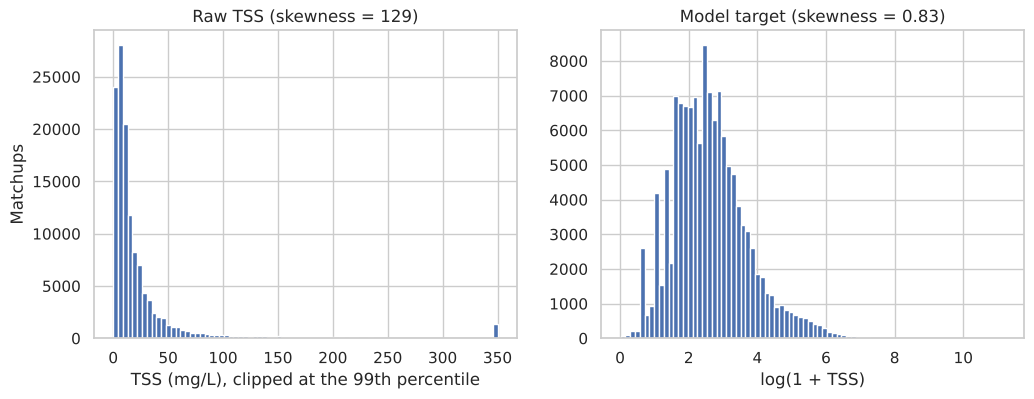

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["tss"].clip(upper=df["tss"].quantile(0.99)), bins=80)
axes[0].set(title=f"Raw TSS (skewness = {df['tss'].skew():.0f})", xlabel="TSS (mg/L), clipped at the 99th percentile",
            ylabel="Matchups")

axes[1].hist(np.log1p(df["tss"]), bins=80)
axes[1].set(title=f"Model target (skewness = {np.log1p(df['tss']).skew():.2f})", xlabel="log(1 + TSS)")

save_fig("01_tss_distribution")

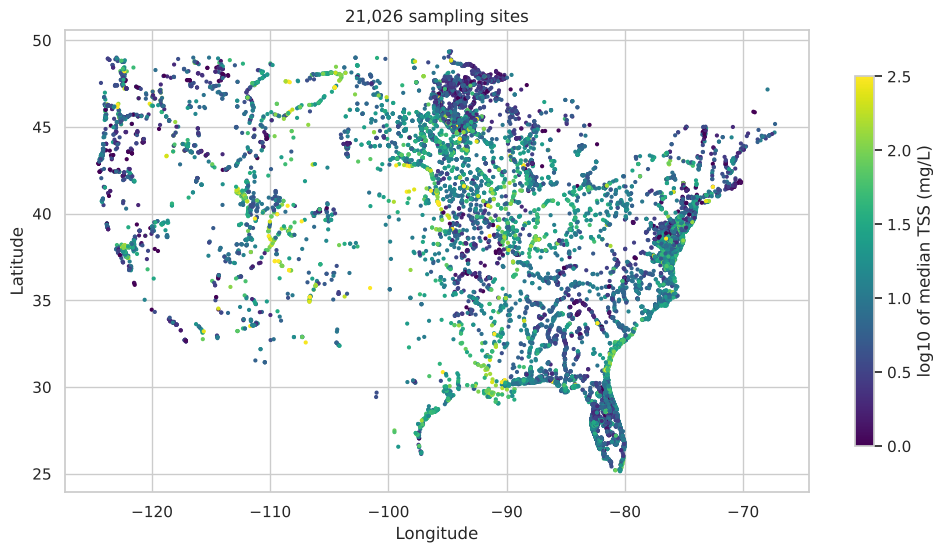

In [7]:
## one dot per site, coloured by the site's median TSS (continental US only)
sites = df.groupby("SiteID").agg(lat=("lat", "first"), long=("long", "first"), tss=("tss", "median"))
sites = sites[sites["long"].between(-130, -60) & sites["lat"].between(23, 52)]

plt.figure(figsize=(12, 6))
plt.scatter(sites["long"], sites["lat"], c=np.log10(sites["tss"]), s=4, cmap="viridis", vmin=0, vmax=2.5)
plt.colorbar(label="log10 of median TSS (mg/L)", shrink=0.8)
plt.title(f"{len(sites):,} sampling sites")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
save_fig("02_site_map")

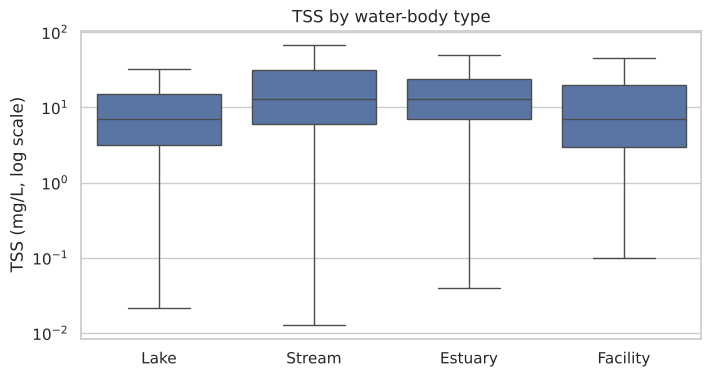

In [8]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="type", y="tss", order=["Lake", "Stream", "Estuary", "Facility"], showfliers=False)
plt.yscale("log")
plt.title("TSS by water-body type")
plt.xlabel("")
plt.ylabel("TSS (mg/L, log scale)")
save_fig("03_tss_by_water_type")

**Observations (EDA)**

- Cleaning keeps **128,603 matchups from 21,129 sites** (1984–2019).
- Half of the data are **streams**, a quarter **estuaries**, a quarter **lakes** — not only lakes.
- TSS is extremely skewed (skewness ≈ 129); `log(1 + TSS)` makes it almost symmetric (0.83).
- Streams and estuaries are more turbid (median 13 mg/L) than lakes (7 mg/L) → water-body type is a useful feature.

## 4. Feature Engineering

| Group | Features | Why |
|---|---|---|
| Landsat bands | `blue`, `green`, `red`, `nir`, `swir1`, `swir2` | Particles scatter light → turbid water is brighter |
| Indices | `NDTI` = (R−G)/(R+G), `NDWI` = (G−NIR)/(G+NIR), `NDSSI` = (B−NIR)/(B+NIR) | Sediment shifts water colour from green to red |
| Ratios, brightness | `R_G`, `R_B`, `G_B`, `NIR_R`, `log_visible` = log(B+G+R) | Ratios cancel part of the lighting / atmosphere effect |
| Season | `doy_sin`, `doy_cos` | Day of year as a cycle (spring runoff, summer algae) |
| **Site context** | `type_Stream`, `type_Estuary`, `type_Facility`, `landsat_7`, `landsat_8` | One-hot water-body type (reference = Lake) and sensor (reference = Landsat 5) |

In [9]:
## target
df["tss_log"] = np.log1p(df["tss"])

## reflectance is stored x 10^4 -> convert to 0–1
df[BANDS] = df[BANDS] / 10000
b, g, r, n = df["blue"], df["green"], df["red"], df["nir"]

## indices and band ratios
df["NDTI"] = (r - g) / (r + g)
df["NDWI"] = (g - n) / (g + n)
df["NDSSI"] = (b - n) / (b + n)
df["R_G"] = r / g
df["R_B"] = r / b
df["G_B"] = g / b
df["NIR_R"] = n / r
df["log_visible"] = np.log(b + g + r)

## season: day of year as a cycle
day = pd.to_datetime(df["date"]).dt.day_of_year
df["doy_sin"] = np.sin(2 * np.pi * day / 365)
df["doy_cos"] = np.cos(2 * np.pi * day / 365)

## site context: one-hot encoding
for t in ["Stream", "Estuary", "Facility"]:
    df[f"type_{t}"] = (df["type"] == t).astype(float)
for s in [7, 8]:
    df[f"landsat_{s}"] = (df["sat"] == s).astype(float)

SPECTRAL = BANDS + ["NDTI", "NDWI", "NDSSI", "R_G", "R_B", "G_B", "NIR_R", "log_visible"]
SEASON = ["doy_sin", "doy_cos"]
CONTEXT = ["type_Stream", "type_Estuary", "type_Facility", "landsat_7", "landsat_8"]
FEATURES = SPECTRAL + SEASON + CONTEXT

X = df[FEATURES]
y = df["tss_log"]
groups = df["SiteID"]
print(f"X: {X.shape[0]:,} rows x {X.shape[1]} features")

X: 128,603 rows x 21 features


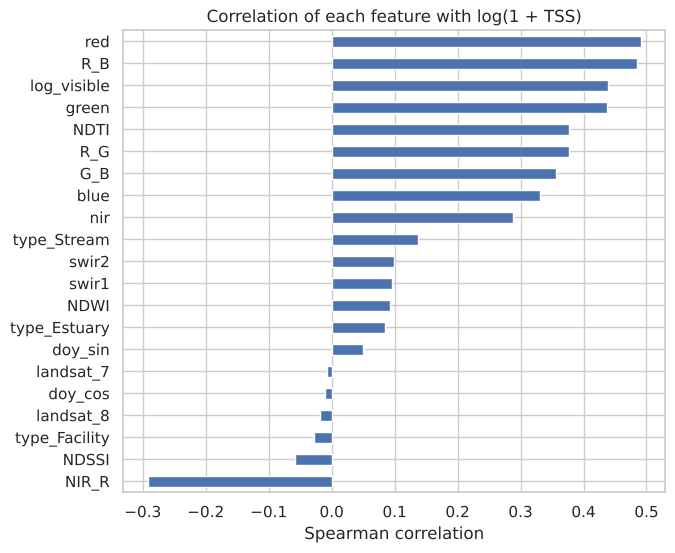

In [10]:
## correlation of each feature with the target (Spearman = rank-based, robust to outliers)
X.corrwith(y, method="spearman").sort_values().plot.barh(figsize=(7, 6))
plt.title("Correlation of each feature with log(1 + TSS)")
plt.xlabel("Spearman correlation")
save_fig("04_feature_target_correlation")

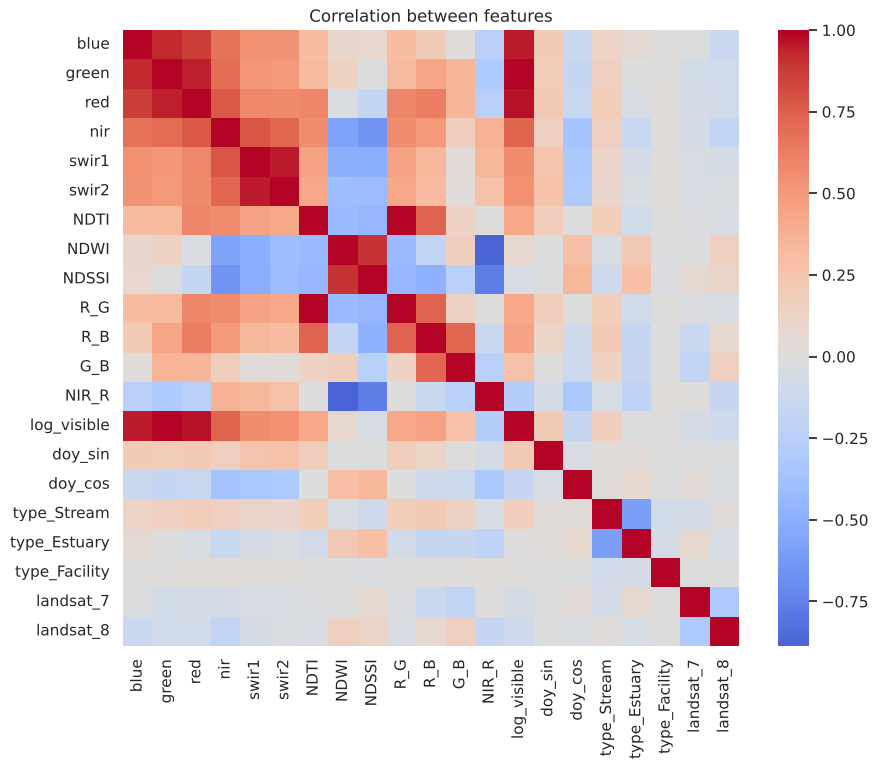

In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(method="spearman"), cmap="coolwarm", center=0, square=True)
plt.title("Correlation between features")
save_fig("05_feature_correlation_heatmap")

**Observations (features)**

- Turbid water is **brighter and redder**: `red`, `R_B`, `log_visible`, `green` and `NDTI` have the strongest positive correlation with TSS.
- Many features are strongly correlated with each other (e.g. `NDTI` is just a transform of `R_G`). This is fine for KNN,
  trees and SVR, but it makes linear coefficients hard to interpret.

## 5. Build Five Machine Learning Models

### 5.1 Train/test split by site

80 % of the **sites** go to training and 20 % to testing. The test set is used **only once**, in Section 7.

In [12]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(f"Train: {len(X_train):,} rows from {g_train.nunique():,} sites")
print(f"Test : {len(X_test):,} rows from {g_test.nunique():,} sites")
print(f"Sites in both sets: {len(set(g_train) & set(g_test))}")

Train: 102,142 rows from 16,903 sites
Test : 26,461 rows from 4,226 sites
Sites in both sets: 0


### 5.2 Outlier handling

Band ratios divide by a reflectance that can be almost zero for very dark water, so a few values are extreme:

In [13]:
X_train[["R_G", "R_B", "G_B", "NIR_R"]].describe(percentiles=[0.001, 0.5, 0.999]).T.round(2)

,count,mean,std,min,0.1%,50%,99.9%,max
R_G,102142.0,0.80,0.16,0.04,0.32,0.80,1.35,2.13
R_B,102142.0,1.03,0.36,0.09,0.34,1.00,2.63,41.50
G_B,102142.0,1.28,0.45,0.35,0.67,1.26,2.79,73.50
NIR_R,102142.0,0.86,0.37,0.00,0.14,0.83,2.67,40.33


**Fix:** clip every spectral feature to its 0.1–99.9th percentile range. The limits are learned from the **training set only**
and then applied to both sets.

In [14]:
low = X_train[SPECTRAL].quantile(0.001)
high = X_train[SPECTRAL].quantile(0.999)
X_train[SPECTRAL] = X_train[SPECTRAL].clip(low, high, axis=1)
X_test[SPECTRAL] = X_test[SPECTRAL].clip(low, high, axis=1)

### 5.3 The five models

| # | Model | Idea | Lecture |
|---|---|---|---|
| 1 | **Linear Regression** | Baseline: a weighted sum of the features | 5 |
| 2 | **Polynomial Ridge** | Adds squared and interaction terms, with an L2 penalty | 6 |
| 3 | **K-Nearest Neighbors (KNN)** | Averages the TSS of the most similar training samples | 4 |
| 4 | **Decision Tree** | Learns if/else threshold rules | 2 |
| 5 | **Support Vector Regression (SVR)** | Smooth non-linear model with an RBF kernel | 3 |

- Models that depend on feature scale get a `StandardScaler` inside a `Pipeline`, so scaling is fitted on the training folds only.
- All models start with the **scikit-learn default** hyperparameters; Section 6 tunes them.
- **SVR is too slow for 100 k rows** (training time grows with the square of the row count), so it is trained on a
  random sample of 15,000 training rows.

In [15]:
def make_models():
    """Return new, unfitted copies of the five models with default hyperparameters."""
    return {
        "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "Polynomial Ridge": Pipeline([("scaler", StandardScaler()),
                                      ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                                      ("model", Ridge(alpha=1))]),
        "KNN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=5))]),
        "Decision Tree": DecisionTreeRegressor(random_state=SEED),
        "SVR": Pipeline([("scaler", StandardScaler()), ("model", SVR(kernel="rbf"))]),
    }


svr_rows = X_train.sample(15000, random_state=SEED).index


def train_data(name, columns=FEATURES):
    """Training data for a model: all rows, or the 15,000-row sample for SVR."""
    rows = svr_rows if name == "SVR" else X_train.index
    return X_train.loc[rows, columns], y_train.loc[rows], g_train.loc[rows]

### 5.4 Baseline: 5-fold cross-validation grouped by site

Each model is trained on 4/5 of the training sites and scored on the other 1/5, five times.
A large gap between Train R² and CV R² means over-fitting.

In [16]:
CV = GroupKFold(n_splits=5)


def cv_r2(name, columns=FEATURES):
    """Mean train R² and mean validation R² over the 5 folds."""
    X_, y_, g_ = train_data(name, columns)
    scores = cross_validate(make_models()[name], X_, y_, groups=g_, cv=CV, scoring="r2",
                            return_train_score=True, n_jobs=-1)
    return scores["train_score"].mean(), scores["test_score"].mean()


baseline = pd.DataFrame({name: cv_r2(name) for name in MODEL_NAMES}, index=["Train R²", "CV R²"]).T
baseline.round(3)

,Train R²,CV R²
Linear Regression,0.413,0.407
Polynomial Ridge,0.476,0.461
KNN,0.631,0.418
Decision Tree,0.993,0.022
SVR,0.512,0.454


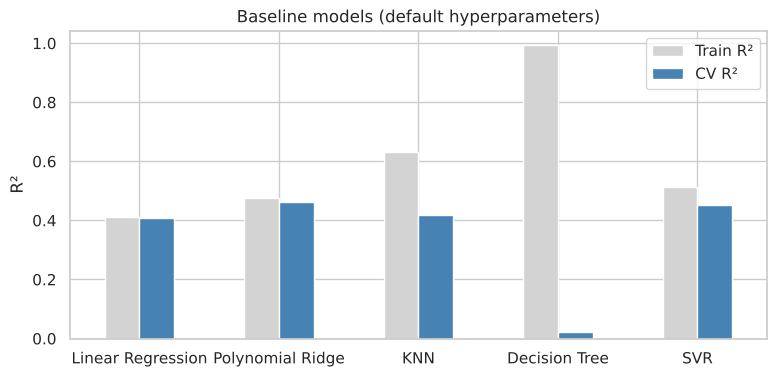

In [17]:
baseline.plot.bar(figsize=(9, 4), color=["lightgray", "steelblue"], rot=0)
plt.title("Baseline models (default hyperparameters)")
plt.ylabel("R²")
save_fig("06_baseline_cv_comparison")

**Observations (baseline)**

- **Linear Regression** (CV R² 0.407): train ≈ CV → it *under-fits*; the relationship is not linear.
- **Polynomial Ridge** and **SVR** are the best defaults (≈ 0.46).
- **KNN** (k = 5) and especially the **Decision Tree** *over-fit*: the tree scores 0.993 on training sites but only 0.022 on new sites.

### 5.5 Does the site context help? (RQ3)

The same cross-validation, without the five site-context features.

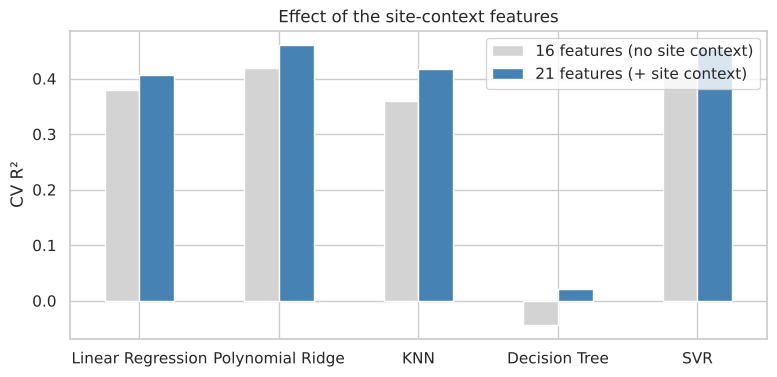

,16 features (no site context),21 features (+ site context),Gain
Linear Regression,0.380,0.407,0.027
Polynomial Ridge,0.420,0.461,0.041
KNN,0.360,0.418,0.058
Decision Tree,-0.043,0.022,0.065
SVR,0.413,0.454,0.041


In [18]:
ablation = pd.DataFrame({
    "16 features (no site context)": [cv_r2(name, SPECTRAL + SEASON)[1] for name in MODEL_NAMES],
    "21 features (+ site context)": baseline["CV R²"].values,
}, index=MODEL_NAMES)

ablation.plot.bar(figsize=(9, 4), color=["lightgray", "steelblue"], rot=0)
plt.title("Effect of the site-context features")
plt.ylabel("CV R²")
save_fig("07_feature_engineering_effect")

ablation["Gain"] = ablation.iloc[:, 1] - ablation.iloc[:, 0]
ablation.round(3)

**Observations (RQ3)**

- Water-body type and sensor improve **every** model (+0.027 to +0.065 CV R²).
- Streams, estuaries and lakes have different sediment sources, so the same colour can mean a different TSS.
- **Answer to RQ3: yes** — all later steps use the 21 features.

## 6. Hyperparameter Tuning

`GridSearchCV` tries every combination and scores it with the same 5-fold grouped cross-validation (training sites only).

| Model | Hyperparameters | What they control |
|---|---|---|
| Polynomial Ridge | `degree`, `alpha` | Flexibility vs. L2 penalty |
| KNN | `n_neighbors`, `weights` | How many neighbours are averaged, and how |
| Decision Tree | `max_depth`, `min_samples_leaf` | Tree size → over-fitting |
| SVR | `C`, `gamma`, `epsilon` | Error penalty, kernel width, tolerance |

Linear Regression has nothing to tune.

In [19]:
PARAM_GRIDS = {
    "Polynomial Ridge": {"poly__degree": [1, 2, 3], "model__alpha": [0.1, 1, 10, 100]},
    "KNN": {"model__n_neighbors": [5, 10, 20, 30, 50, 80], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"max_depth": [4, 6, 8, 10, 12, 15, 20, None], "min_samples_leaf": [1, 10, 30, 100]},
    "SVR": {"model__C": [1, 3, 10], "model__gamma": ["scale", 0.1], "model__epsilon": [0.1, 0.3]},
}

searches = {}
for name, grid in PARAM_GRIDS.items():
    X_, y_, g_ = train_data(name)
    search = GridSearchCV(make_models()[name], grid, cv=CV, scoring="r2", n_jobs=-1)
    search.fit(X_, y_, groups=g_)
    searches[name] = search
    print(f"{name:<17} best CV R² = {search.best_score_:.3f}  {search.best_params_}")

Polynomial Ridge  best CV R² = 0.465  {'model__alpha': 100, 'poly__degree': 3}


KNN               best CV R² = 0.497  {'model__n_neighbors': 30, 'model__weights': 'distance'}


Decision Tree     best CV R² = 0.425  {'max_depth': 12, 'min_samples_leaf': 100}


SVR               best CV R² = 0.459  {'model__C': 1, 'model__epsilon': 0.3, 'model__gamma': 'scale'}


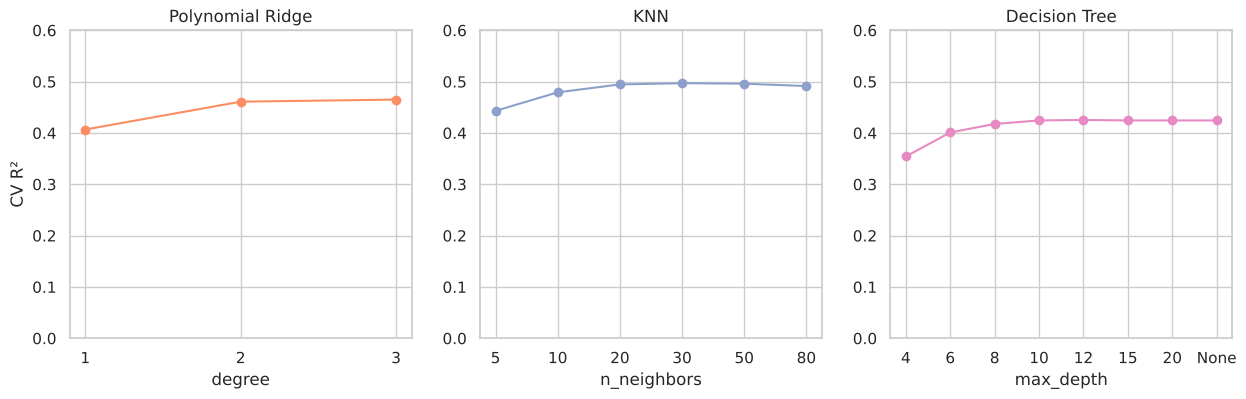

In [20]:
## CV R² along one hyperparameter (the other one fixed at its best value)
curves = [("Polynomial Ridge", "poly__degree", "model__alpha"),
          ("KNN", "model__n_neighbors", "model__weights"),
          ("Decision Tree", "max_depth", "min_samples_leaf")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, param, other) in zip(axes, curves):
    results = pd.DataFrame(searches[name].cv_results_)
    results = results[results["param_" + other] == searches[name].best_params_[other]]
    labels = [str(p[param]) for p in results["params"]]
    ax.plot(labels, results["mean_test_score"], marker="o", color=COLORS[name])
    ax.set(title=name, xlabel=param.split("__")[-1], ylim=(0, 0.6))
axes[0].set_ylabel("CV R²")
save_fig("08_validation_curves")

Best model: KNN


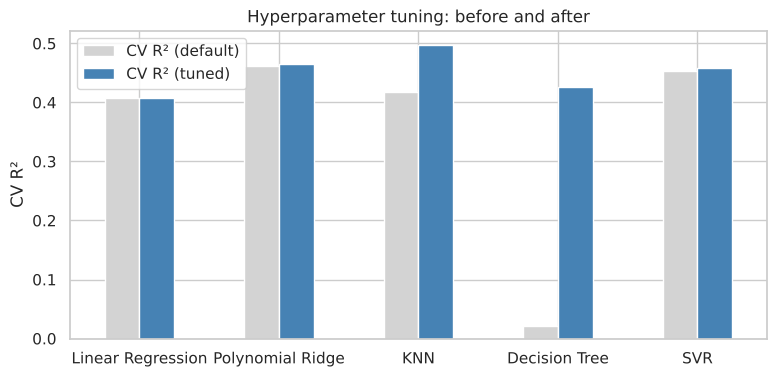

,CV R² (default),CV R² (tuned),Gain
Linear Regression,0.407,0.407,0.000
Polynomial Ridge,0.461,0.465,0.004
KNN,0.418,0.497,0.079
Decision Tree,0.022,0.425,0.404
SVR,0.454,0.459,0.005


In [21]:
tuning = pd.DataFrame({"CV R² (default)": baseline["CV R²"], "CV R² (tuned)": baseline["CV R²"]})
for name, search in searches.items():
    tuning.loc[name, "CV R² (tuned)"] = search.best_score_
tuning["Gain"] = tuning["CV R² (tuned)"] - tuning["CV R² (default)"]

BEST = tuning["CV R² (tuned)"].idxmax()     # chosen by cross-validation, before looking at the test set
print("Best model:", BEST)

tuning[["CV R² (default)", "CV R² (tuned)"]].plot.bar(figsize=(9, 4), color=["lightgray", "steelblue"], rot=0)
plt.title("Hyperparameter tuning: before and after")
plt.ylabel("CV R²")
save_fig("09_tuning_before_after")

tuning.round(3)

**Observations (tuning)**

| Model | Best hyperparameters | CV R² before → after |
|---|---|---|
| Decision Tree | `max_depth=12`, `min_samples_leaf=100` | 0.022 → **0.425** |
| KNN | `n_neighbors=30`, `weights=distance` | 0.418 → **0.497** |
| SVR | `C=1`, `epsilon=0.3`, `gamma=scale` | 0.454 → 0.459 |
| Polynomial Ridge | `degree=3`, `alpha=100` | 0.461 → 0.465 |

- Tuning helps most for the models that over-fit by default (tree, KNN).
- **Best model by cross-validation: KNN** — chosen before looking at the test set.

## 7. Model Evaluation on Unseen Sites

The tuned models are trained on the training set and evaluated **once** on the test set.

- **R², RMSE, MAE** — on `log(1 + TSS)`.
- **Within 2× (%)** — share of predictions between half and double the measured TSS.

In [22]:
def evaluate(y_true, y_pred):
    error = y_pred - y_true
    return {"R²": r2_score(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "Within 2× (%)": np.mean(np.abs(error) <= np.log(2)) * 100}


## GridSearchCV already refitted the best version of each tuned model on its training data
final_models = {"Linear Regression": make_models()["Linear Regression"].fit(X_train, y_train)}
for name, search in searches.items():
    final_models[name] = search.best_estimator_

predictions = {name: final_models[name].predict(X_test) for name in MODEL_NAMES}
test_results = pd.DataFrame({name: evaluate(y_test, predictions[name]) for name in MODEL_NAMES}).T
test_results.round(3)

,R²,RMSE,MAE,Within 2× (%)
Linear Regression,0.447,0.844,0.628,65.636
Polynomial Ridge,0.503,0.800,0.590,68.433
KNN,0.529,0.778,0.547,70.685
Decision Tree,0.469,0.826,0.616,66.517
SVR,0.499,0.803,0.590,68.607


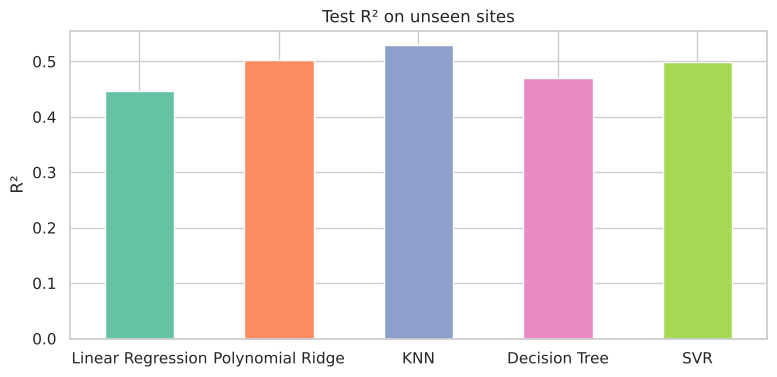

In [23]:
test_results["R²"].plot.bar(figsize=(9, 4), color=[COLORS[name] for name in MODEL_NAMES], rot=0)
plt.title("Test R² on unseen sites")
plt.ylabel("R²")
save_fig("10_test_r2")

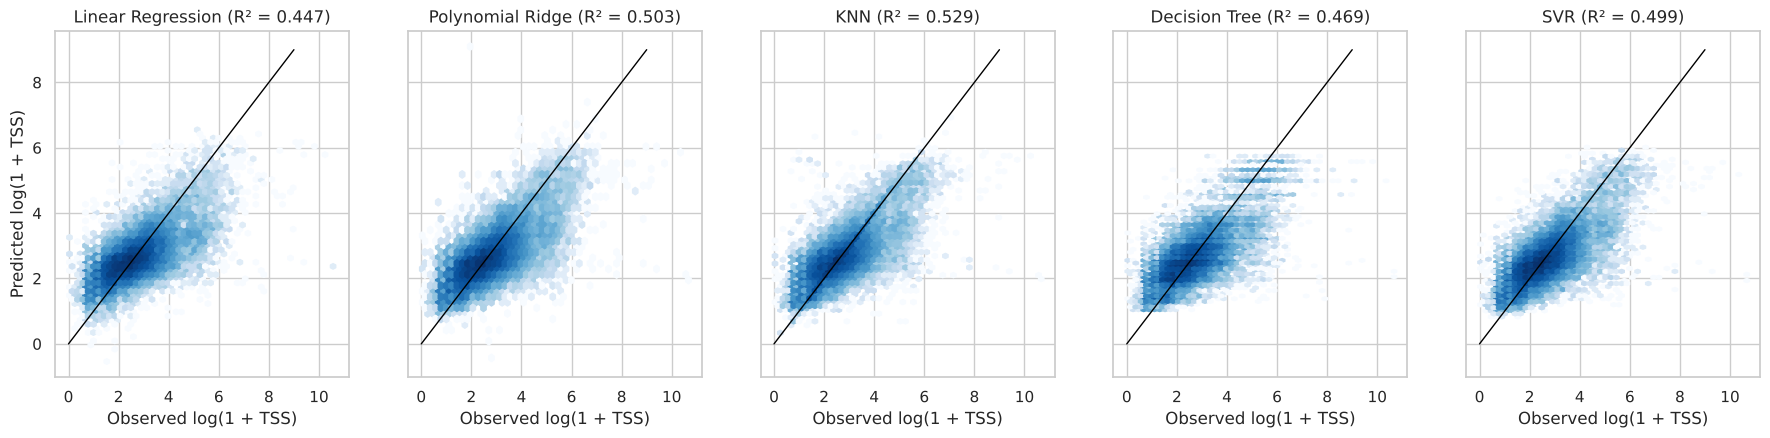

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    ax.hexbin(y_test, predictions[name], gridsize=50, cmap="Blues", bins="log")
    ax.plot([0, 9], [0, 9], color="black", linewidth=1)          # perfect prediction
    ax.set(title=f"{name} (R² = {test_results.loc[name, 'R²']:.3f})", xlabel="Observed log(1 + TSS)")
axes[0].set_ylabel("Predicted log(1 + TSS)")
save_fig("11_predicted_vs_observed")

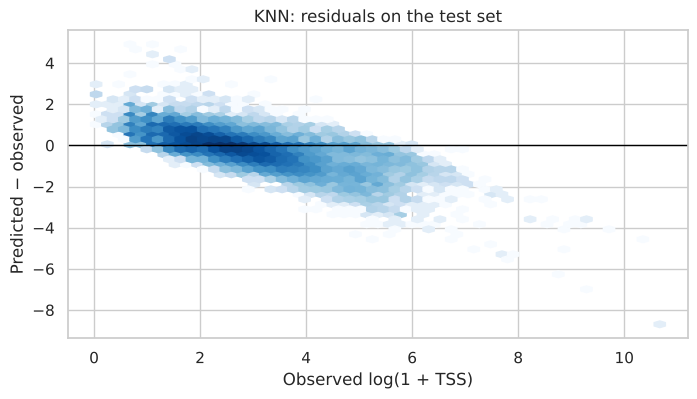

In [25]:
plt.figure(figsize=(8, 4))
plt.hexbin(y_test, predictions[BEST] - y_test, gridsize=50, cmap="Blues", bins="log")
plt.axhline(0, color="black", linewidth=1)
plt.title(f"{BEST}: residuals on the test set")
plt.xlabel("Observed log(1 + TSS)")
plt.ylabel("Predicted − observed")
save_fig("12_residuals_best_model")

### 7.1 Where does the best model work well? (RQ5)

In [26]:
type_test = df["type"].iloc[test_idx]
rows = {}
for t in ["Stream", "Estuary", "Lake", "Facility"]:
    mask = (type_test == t).values
    rows[t] = {"matchups": mask.sum(), **evaluate(y_test[mask], predictions[BEST][mask])}
pd.DataFrame(rows).T.round(3)

,matchups,R²,RMSE,MAE,Within 2× (%)
Stream,12551.0,0.563,0.848,0.574,69.062
Estuary,7383.0,0.287,0.674,0.511,71.908
Lake,6246.0,0.440,0.694,0.508,73.967
Facility,281.0,-0.011,1.497,1.125,38.078


### 7.2 Can it tell clear water from turbid water?

For management, a class is often enough. Illustrative classes (not a legal standard):
**Low** < 10 mg/L, **Moderate** 10–50 mg/L, **High** ≥ 50 mg/L.

Accuracy: 69.4%
Always guessing 'Moderate': 44.7%


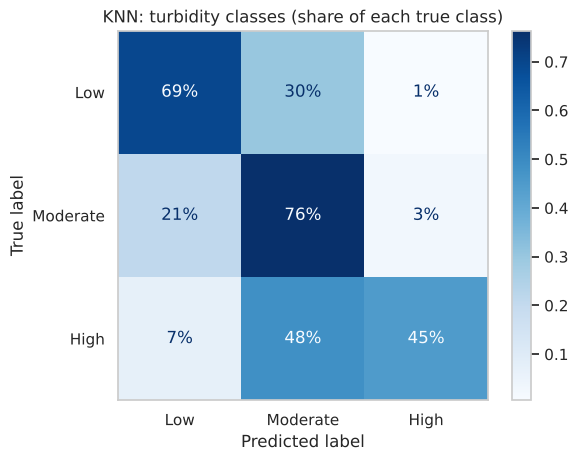

In [27]:
def to_class(tss_log):
    tss = np.expm1(tss_log)                        # back to mg/L
    return np.where(tss < 10, "Low", np.where(tss < 50, "Moderate", "High"))


true_class = to_class(y_test.values)
pred_class = to_class(predictions[BEST])
print(f"Accuracy: {accuracy_score(true_class, pred_class):.1%}")
print(f"Always guessing 'Moderate': {np.mean(true_class == 'Moderate'):.1%}")

ConfusionMatrixDisplay.from_predictions(true_class, pred_class, labels=["Low", "Moderate", "High"],
                                        normalize="true", values_format=".0%", cmap="Blues")
plt.grid(False)
plt.title(f"{BEST}: turbidity classes (share of each true class)")
save_fig("13_turbidity_class_confusion")

**Observations (evaluation)**

- **KNN is also best on the test set**: R² = 0.529, MAE = 0.547, **70.7 %** of predictions within 2× of the measured TSS
  (Linear Regression: R² 0.447, 65.6 %). The ranking matches cross-validation.
- **All models compress the range**: clear water is over-predicted and very turbid water (> 1,000 mg/L) strongly under-predicted.
- **By water-body type:** streams R² 0.563, lakes 0.440, estuaries 0.287 (narrow TSS range, but the best within-2× of 72 %);
  rare facility sites ≈ 0.
- **Turbidity classes:** 69.4 % accuracy vs. 44.7 % for always guessing "Moderate". Extremes are rarely confused
  (1 % of clear water called "High"), but about half of the high-TSS samples are called "Moderate".

## 8. Feature Importance (Explainable ML)

1. **Permutation importance** (all five models): shuffle one feature in the test set and measure the drop in R².
2. **SHAP** (best model): how much each feature pushes a single prediction up or down.
3. **Decision-tree rules**: the first splits of the tuned tree.

### 8.1 Permutation importance

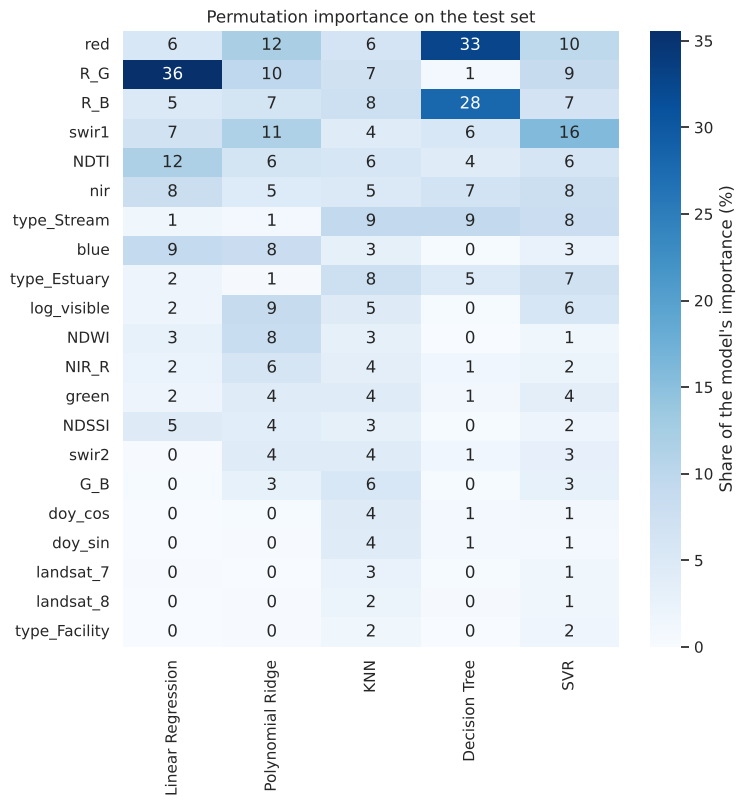

In [28]:
X_sample = X_test.sample(3000, random_state=SEED)       # a sample keeps KNN and SVR fast
y_sample = y_test.loc[X_sample.index]

importance = pd.DataFrame(index=FEATURES)
for name in MODEL_NAMES:
    result = permutation_importance(final_models[name], X_sample, y_sample, scoring="r2",
                                    n_repeats=5, random_state=SEED, n_jobs=-1)
    importance[name] = result.importances_mean

## show each model's importance as a share of its own total, so the models can be compared
share = importance.clip(lower=0) / importance.clip(lower=0).sum() * 100
share = share.loc[share.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(8, 8))
sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Share of the model's importance (%)"})
plt.title("Permutation importance on the test set")
save_fig("14_permutation_importance")

### 8.2 SHAP values for the best model

Each dot is one prediction. Position = effect on the predicted `log(1 + TSS)`; colour = feature value (red = high).

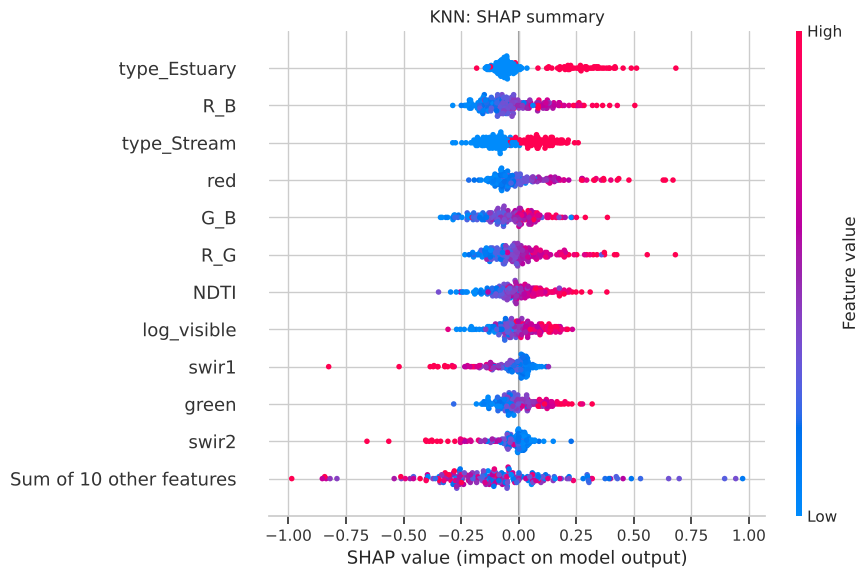

In [29]:
background = X_train.sample(25, random_state=SEED)       # reference data
X_explain = X_test.sample(200, random_state=SEED)        # predictions to explain

explainer = shap.PermutationExplainer(final_models[BEST].predict, background, seed=SEED)
shap_values = explainer(X_explain, max_evals=100, silent=True)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title(f"{BEST}: SHAP summary")
save_fig("15_shap_summary_best_model")

### 8.3 Decision-tree rules

Tuned tree: depth = 12, leaves = 689


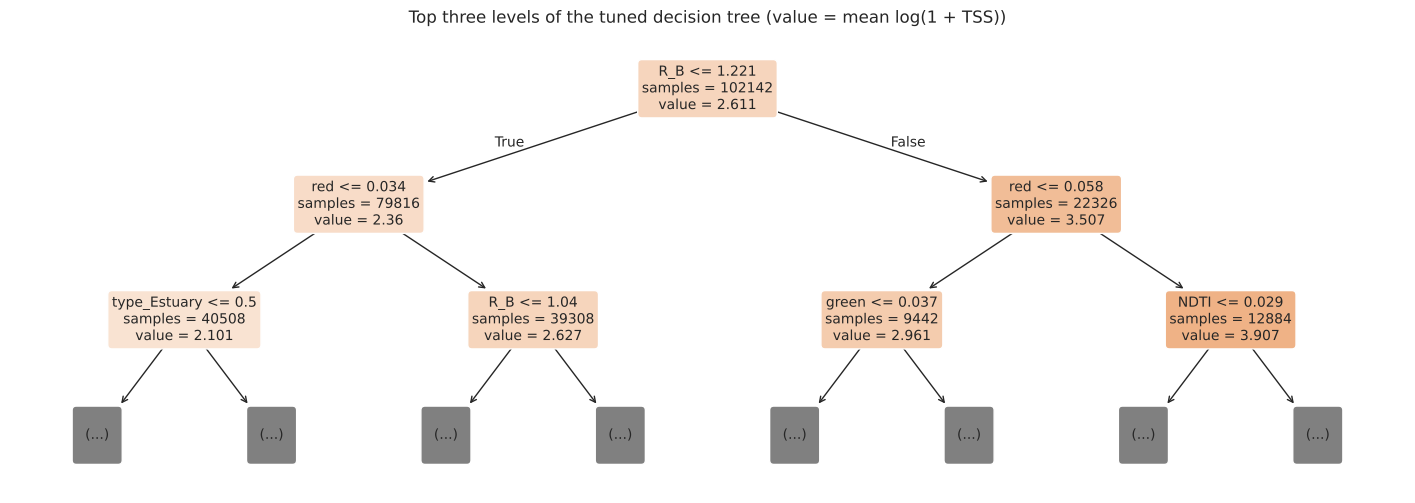

In [30]:
tree = final_models["Decision Tree"]
print(f"Tuned tree: depth = {tree.get_depth()}, leaves = {tree.get_n_leaves():,}")

plt.figure(figsize=(18, 6))
plot_tree(tree, max_depth=2, feature_names=FEATURES, filled=True, rounded=True, impurity=False, fontsize=10)
plt.title("Top three levels of the tuned decision tree (value = mean log(1 + TSS))")
save_fig("16_decision_tree_top_levels")

**Observations (explainable ML)**

- **Red-band information drives every model**: `red`, `R_B`, `R_G` and `NDTI` are at the top for all five models.
  The tree's first rule is `R_B ≤ 1.22` (redder water → higher TSS).
- **KNN** also relies strongly on **water-body type** (`type_Stream`, `type_Estuary`).
- **SHAP directions:** high `R_B`, `red`, `R_G`, `NDTI` → higher TSS; stream or estuary → higher TSS;
  high `swir1` / `swir2` → **lower** TSS (SWIR over water usually means glint or haze, not sediment).
- Season and sensor matter little.

## 9. Environmental Interpretation

- **Physically sensible.** Suspended particles scatter red light back out of the water, so turbid water looks brighter
  and redder. The top features measure exactly this.
- **Setting matters.** Streams carry erosion and runoff sediment, estuaries are stirred by tides, lakes let particles
  settle — so water-body type is a strong predictor.
- **Useful for:** screening thousands of unsampled water bodies, choosing where to sample, and long-term turbidity
  trends from the Landsat archive (since 1984).
- **Not good enough for:** regulatory compliance, which needs exact concentrations.
- **Main weakness:** storm, flood and dredging plumes (hundreds–thousands of mg/L) are under-predicted — they are rare
  in the data, reflectance saturates at high sediment loads, and TSS can change within hours of the image.

**Room for improvement:** add rainfall, streamflow and land use; keep only same-day matchups; give more weight to rare
high-TSS events; validate by whole watersheds; try ensemble models (Random Forest, XGBoost).

### Answers to the research questions

| | Answer |
|---|---|
| **RQ1** Predict TSS at unseen sites? | **Moderately**: test R² = 0.529, 70.7 % of predictions within 2×. Good for relative monitoring. |
| **RQ2** Best model? Does tuning help? | **KNN** (k = 30). All non-linear models beat Linear Regression. Tuning was decisive for the tree (+0.40) and KNN (+0.08). |
| **RQ3** Does site context help? | **Yes**, +0.03 to +0.07 CV R² for every model. |
| **RQ4** Key features? | Red-band features (`red`, `R_B`, `R_G`, `NDTI`) and water-body type — consistent with sediment optics. |
| **RQ5** Where does it fail? | Very turbid water is under-predicted; weaker on estuaries and rare facility sites. |

In [31]:
## final summary
summary = test_results.copy()
summary.insert(0, "CV R² (tuned)", tuning["CV R² (tuned)"])
print("Best model:", BEST)
summary.round(3)

Best model: KNN


,CV R² (tuned),R²,RMSE,MAE,Within 2× (%)
Linear Regression,0.407,0.447,0.844,0.628,65.636
Polynomial Ridge,0.465,0.503,0.800,0.590,68.433
KNN,0.497,0.529,0.778,0.547,70.685
Decision Tree,0.425,0.469,0.826,0.616,66.517
SVR,0.459,0.499,0.803,0.590,68.607
